Device: cuda
Dataset root: /kaggle/input/datasets/nocturnalnerd/balanced-dataset-701020/dataset_result_70_10_20_balanced
Manifest path: /kaggle/input/datasets/nocturnalnerd/balanced-dataset-701020/dataset_result_70_10_20_balanced/manifest.csv


Cloning into '/kaggle/working/FreqNet-DeepfakeDetection'...



Loaded manifest: 55,338 rows, columns: ['split', 'label', 'relative_path', 'source_dataset', 'source_model', 'original_path', 'sha256']
Unique 'split' values: ['train', 'validation', 'test']
Unique 'label' values: ['fake', 'real']
Unique 'source_dataset' values (sample): ['diffusion_defactify', 'gan']
Unique 'source_model' values (sample): ['dalle3', 'midjourney6', 'sd21', 'sd3', 'sdxl', 'AttGAN', 'BEGAN', 'CramerGAN', 'InfoMaxGAN', 'MMDGAN', 'RelGAN', 'S3GAN', 'SNGAN', 'STGAN', 'real']

Path check: 200/200 sampled relative_path values resolve under /kaggle/input/datasets/nocturnalnerd/balanced-dataset-701020/dataset_result_70_10_20_balanced (100.0%)

Validation rows matched: 5,534  |  Test rows matched: 11,068
Loading models...

Selecting F1-max threshold per model on the CLEAN validation split...


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 4, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 4, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


infer:   0%|          | 0/346 [00:00<?, ?it/s]

  original_freqnet: threshold=0.875  (val F1=0.9353)
  dynamic_freqnet: threshold=0.915  (val F1=0.9713)

=== Condition: clean (downscale=1.0, clean=True) ===


... (14 outputs left out)

  original_freqnet  AUC=0.9219 [0.9169,0.9264]  acc=0.8564  real_recall=0.9284  fake_recall=0.7844
  dynamic_freqnet   AUC=0.9291 [0.9241,0.9337]  acc=0.8806  real_recall=0.9595  fake_recall=0.8016

=== Condition: q15 (downscale=1.0, clean=False) ===


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 4, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 4, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


infer:   0%|          | 0/692 [00:00<?, ?it/s]

  original_freqnet  AUC=0.9150 [0.9093,0.9198]  acc=0.8567  real_recall=0.9501  fake_recall=0.7633
  dynamic_freqnet   AUC=0.9209 [0.9155,0.9260]  acc=0.8860  real_recall=0.9747  fake_recall=0.7973

Saved: jpeg_overall_metrics.csv, jpeg_domain_breakdown.csv, jpeg_per_generator_detection_rate.csv -> /kaggle/working/jpeg_robustness_matched
Saved: jpeg_robustness_curves.png

SUMMARY
original_freqnet: AUC drop clean->q15 = +0.0694  (real recall drop = -0.0199, fake recall drop = +0.1747)
dynamic_freqnet: AUC drop clean->q15 = +0.0749  (real recall drop = +0.0009, fake recall drop = +0.1652)

How to read this:
- If dynamic_freqnet's clean-test AUC advantage over original_freqnet SHRINKS
  or REVERSES as quality drops, that is consistent with the advantage coming
  from low/mid-frequency content that compression scrambles (a shortcut),
  not from genuine generative artifacts that FreqNet's own later frequency
  layers also key on.
- If the advantage is stable across quality levels, that argu

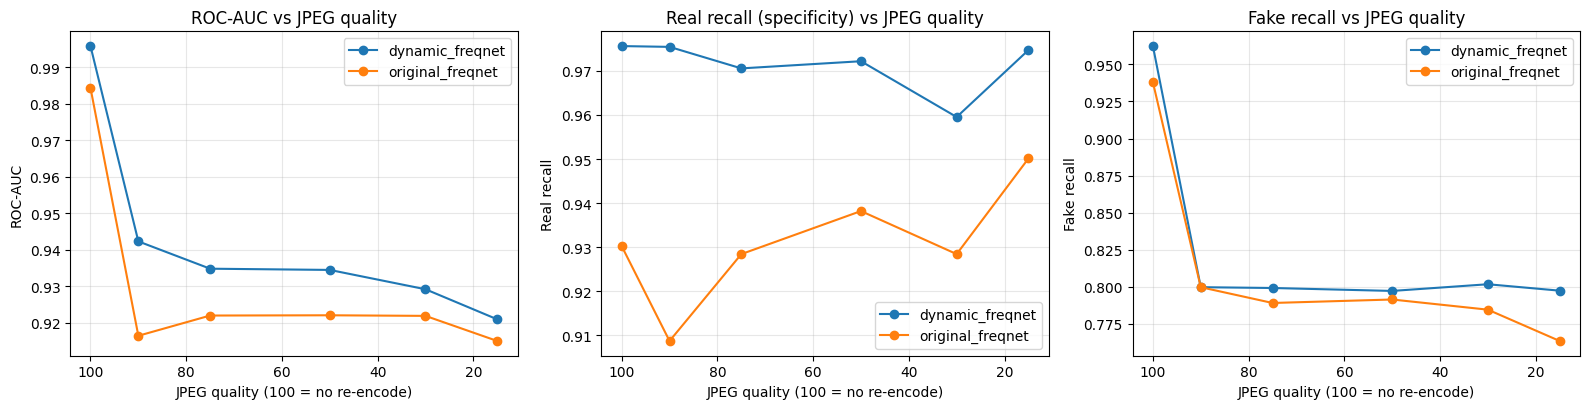

In [1]:
"""
JPEG-compression robustness: matched Original FreqNet vs matched Dynamic FreqNet
=================================================================================
Both checkpoints must come from DynamicFreqnet_matched.py (INPUT_MODE="rgb_baseline"
and INPUT_MODE="dynamic") so the ONLY architectural difference is the first
frequency step -- see that script's docstring.

Purpose
-------
Dynamic FreqNet's fixed cutoff (r0=0.20) suppresses far less of the spectrum
than Original's fixed square (~6% vs ~25% of the area), so it lets through much
more low-to-mid-frequency content. If Dynamic's clean-test advantage comes from
that extra low-frequency content carrying a resolution/compression/resizing
shortcut rather than genuine generative artifacts, its advantage should shrink
or invert as JPEG quality drops and that low-frequency structure is scrambled
by compression. If the advantage survives compression, that argues against the
shortcut explanation.

This script reports, per model per JPEG quality:
  - overall ROC-AUC / AP / accuracy (with bootstrap CI on AUC)
  - real recall (specificity) and fake recall SEPARATELY -- if one model's
    real recall collapses under compression while its fake recall does not
    (or vice versa), that asymmetry is itself diagnostic of a shortcut
  - the same split by source_dataset (gan vs diffusion), since a resolution/
    format confound would likely hit one domain harder than the other
  - per-generator fake recall (Wilson 95% CI), same convention as
    ComparingModels_matched.py

Threshold policy: each model's decision threshold is selected ONCE on the
CLEAN validation split (F1-maximizing, matching Section III.E) and then held
FIXED across all JPEG conditions -- this is the standard robustness-evaluation
protocol; re-tuning the threshold per corruption would hide exactly the
degradation this script exists to measure.

Run this in the same Colab/Kaggle GPU environment as your other scripts.
"""

from __future__ import annotations

import io
import math
import os
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image, ImageFile
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score,
    brier_score_loss, cohen_kappa_score, confusion_matrix, f1_score,
    log_loss, precision_score, recall_score, roc_auc_score,
)
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from tqdm.auto import tqdm

ImageFile.LOAD_TRUNCATED_IMAGES = True

# -----------------------------------------------------------------------------
# 0. Configuration
# -----------------------------------------------------------------------------

SEED = 42
IMAGE_SIZE = 256
BATCH_SIZE = 16
NUM_WORKERS = 8
N_THRESHOLD_CANDIDATES = 181       # matches Section III.E: sweep [0.05, 0.95]
N_BOOTSTRAP = 1000                 # bootstrap resamples for the AUC CI

# JPEG quality levels to test, high -> low. 100 still re-encodes (near-lossless);
# "clean" (no re-encoding at all) is added automatically as the reference point.
JPEG_QUALITY_LEVELS = [90, 75, 50, 30, 15]
# Set > 0 to also downscale-then-upscale before JPEG (simulates a social-media
# resize+recompress pipeline); 1.0 = pure JPEG compression, no resizing.
DOWNSCALE_FACTOR = 1.0

# Must match the training run that produced each checkpoint.
MID_HIGH_CUTOFF = 0.20
NUM_BANDS = 8
SELECTOR_HIDDEN = 32

# >>> Point these at your two matched checkpoints. <<<
ORIGINAL_FREQNET_CHECKPOINT_PATH = Path("/kaggle/input/datasets/mikekomari/models/best_freqnet_rgb_baseline (1).pt")
DYNAMIC_CHECKPOINT_PATH = Path("/kaggle/input/datasets/mikekomari/dynamiccc/best_freqnet_dynamic_c0.20_seed42 (2).pt")

DATASET_HANDLE = "nocturnalnerd/balanced-dataset-701020"
MANIFEST_PATH_OVERRIDE: Path | None = None
VALIDATION_SPLIT_VALUES = {"validation", "val", "valid"}
TEST_SPLIT_VALUES = {"test"}

REPO_DIR = Path("/kaggle/working/FreqNet-DeepfakeDetection")
REPO_URL = "https://github.com/chuangchuangtan/FreqNet-DeepfakeDetection.git"

OUTPUT_DIR = Path("/kaggle/working/jpeg_robustness_matched")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(SEED)
np.random.seed(SEED)
print("Device:", device)


def resolve_dataset_root() -> Path:
    explicit_root = os.environ.get("DATASET_ROOT")
    if explicit_root:
        explicit_path = Path(explicit_root)
        if explicit_path.exists():
            return explicit_path
        raise FileNotFoundError(f"DATASET_ROOT={explicit_path} does not exist.")
    try:
        import kagglehub
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"], check=True)
        import kagglehub
    downloaded_root = Path(kagglehub.dataset_download(DATASET_HANDLE))
    direct = downloaded_root / "dataset_result_70_10_20_balanced"
    if direct.exists():
        return direct
    discovered = [p for p in downloaded_root.rglob("dataset_result_70_10_20_balanced") if p.is_dir()]
    if len(discovered) == 1:
        return discovered[0]
    if all((downloaded_root / split).is_dir() for split in ("train", "validation", "test")):
        return downloaded_root
    raise FileNotFoundError(f"Could not locate dataset_result_balanced under {downloaded_root}.")

DATASET_ROOT = resolve_dataset_root()
MANIFEST_PATH = MANIFEST_PATH_OVERRIDE or (DATASET_ROOT / "manifest.csv")
print("Dataset root:", DATASET_ROOT)
print("Manifest path:", MANIFEST_PATH)

if not REPO_DIR.exists():
    subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(REPO_DIR)], check=True)
freqnet_source = REPO_DIR / "networks" / "freqnet.py"
source_text = freqnet_source.read_text(encoding="utf-8")
patched_text = source_text.replace(".cuda()", "")
if patched_text != source_text:
    freqnet_source.write_text(patched_text, encoding="utf-8")
sys.path.insert(0, str(REPO_DIR))
from networks.freqnet import FreqNet  # noqa: E402


# -----------------------------------------------------------------------------
# 1. Manifest loading -- identical to ComparingModels_matched.py
# -----------------------------------------------------------------------------

def normalize_label(value) -> int:
    if isinstance(value, (int, float)) and not isinstance(value, bool) and not pd.isna(value):
        if int(value) in (0, 1):
            return int(value)
    text = str(value).strip().lower()
    if text in {"0", "real", "authentic", "genuine"}:
        return 0
    if text in {"1", "fake", "synthetic", "generated", "ai", "ai-generated", "ai_generated"}:
        return 1
    raise ValueError(
        f"Unrecognized label value: {value!r}. Edit normalize_label() in this script to handle it, "
        f"or tell me the unique label values printed above and I'll update it for you."
    )


def load_and_validate_manifest(manifest_path: Path, dataset_root: Path) -> pd.DataFrame:
    if not manifest_path.exists():
        raise FileNotFoundError(f"manifest.csv not found at {manifest_path}. Set MANIFEST_PATH_OVERRIDE.")

    df = pd.read_csv(manifest_path)
    print(f"\nLoaded manifest: {len(df):,} rows, columns: {list(df.columns)}")

    required_cols = {"split", "label", "relative_path", "source_model", "source_dataset"}
    missing = required_cols - set(df.columns)
    if missing:
        raise ValueError(f"manifest.csv is missing expected columns: {missing}. Found: {list(df.columns)}")

    print("Unique 'split' values:", df["split"].astype(str).str.strip().unique().tolist())
    print("Unique 'label' values:", df["label"].astype(str).str.strip().unique().tolist()[:10])
    print("Unique 'source_dataset' values (sample):", df["source_dataset"].astype(str).unique().tolist()[:10])
    print("Unique 'source_model' values (sample):", df["source_model"].astype(str).unique().tolist()[:15])

    df["split_norm"] = df["split"].astype(str).str.strip().str.lower()
    df["label_binary"] = df["label"].apply(normalize_label)

    sample_n = min(200, len(df))
    sample = df.sample(sample_n, random_state=SEED)
    exists_mask = sample["relative_path"].apply(lambda p: (dataset_root / str(p)).exists())
    hit_rate = exists_mask.mean()
    print(f"\nPath check: {int(exists_mask.sum())}/{sample_n} sampled relative_path values "
          f"resolve under {dataset_root} ({hit_rate:.1%})")

    if hit_rate < 0.95:
        print("\nExample relative_path values that did NOT resolve:")
        for p in sample.loc[~exists_mask, "relative_path"].head(5):
            print(" ", p, "->", dataset_root / str(p))
        if "original_path" in df.columns:
            print("\nFor reference, 'original_path' for those same rows:")
            print(sample.loc[~exists_mask, "original_path"].head(5).to_list())
        raise FileNotFoundError(
            "Fewer than 95% of sampled relative_path values resolve under DATASET_ROOT. "
            "relative_path is probably relative to something other than DATASET_ROOT, or "
            "DATASET_ROOT itself is wrong. Send me a few example rows (relative_path, "
            "original_path, split) and I will fix the join logic before you run this for real."
        )

    return df


manifest_df = load_and_validate_manifest(MANIFEST_PATH, DATASET_ROOT)

val_df = manifest_df[manifest_df["split_norm"].isin(VALIDATION_SPLIT_VALUES)].reset_index(drop=True)
test_df = manifest_df[manifest_df["split_norm"].isin(TEST_SPLIT_VALUES)].reset_index(drop=True)
print(f"\nValidation rows matched: {len(val_df):,}  |  Test rows matched: {len(test_df):,}")
if len(val_df) == 0 or len(test_df) == 0:
    raise ValueError(
        "Matched 0 rows for validation or test. VALIDATION_SPLIT_VALUES / TEST_SPLIT_VALUES don't "
        "match the unique 'split' values printed above -- update them and rerun."
    )





# -----------------------------------------------------------------------------
# 2. Degradation + manifest-driven dataset (keeps source_model/source_dataset)
# -----------------------------------------------------------------------------


class JpegDegradation:
    """clean=True bypasses entirely. Otherwise: optional downscale (bilinear),
    JPEG-encode in memory at `jpeg_quality`, optional upscale back (bicubic).
    With DOWNSCALE_FACTOR=1.0 this is pure JPEG re-compression at the original
    resolution (the resize is a no-op)."""

    def __init__(self, jpeg_quality: int = 80, downscale_factor: float = 1.0, clean: bool = False):
        self.jpeg_quality = jpeg_quality
        self.downscale_factor = downscale_factor
        self.clean = clean

    def __call__(self, img: Image.Image) -> Image.Image:
        img = img.convert("RGB")
        if self.clean:
            return img
        w, h = img.size
        if self.downscale_factor != 1.0:
            new_w, new_h = max(1, int(w * self.downscale_factor)), max(1, int(h * self.downscale_factor))
            img = img.resize((new_w, new_h), Image.Resampling.BILINEAR)
        buffer = io.BytesIO()
        img.save(buffer, format="JPEG", quality=self.jpeg_quality)
        buffer.seek(0)
        img = Image.open(buffer).convert("RGB")
        if self.downscale_factor != 1.0:
            img = img.resize((w, h), Image.Resampling.BICUBIC)
        return img


class ManifestImageDataset(Dataset):
    def __init__(self, df: pd.DataFrame, image_root: Path, degrade: JpegDegradation):
        self.df = df.reset_index(drop=True)
        self.image_root = Path(image_root)
        self.tfm = transforms.Compose(
            [degrade, transforms.Resize((IMAGE_SIZE, IMAGE_SIZE), antialias=True), transforms.ToTensor()]
        )

    def __len__(self) -> int:
        return len(self.df)

    def __getitem__(self, idx: int):
        row = self.df.iloc[idx]
        image = Image.open(self.image_root / str(row["relative_path"]))
        image = self.tfm(image)
        label = torch.tensor(float(row["label_binary"]), dtype=torch.float32)
        return image, label, str(row["source_model"]), str(row["source_dataset"])


def build_loader(df: pd.DataFrame, quality: int | None, clean: bool) -> DataLoader:
    degrade = JpegDegradation(jpeg_quality=quality if quality is not None else 100,
                               downscale_factor=DOWNSCALE_FACTOR, clean=clean)
    dataset = ManifestImageDataset(df, DATASET_ROOT, degrade)
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS,
                       pin_memory=(device.type == "cuda"))


CONDITIONS = [("clean", None, True)] + [(f"q{q}", q, False) for q in JPEG_QUALITY_LEVELS]


# -----------------------------------------------------------------------------
# 3. Model classes -- copied verbatim from DynamicFreqnet_matched.py
# -----------------------------------------------------------------------------

class AmpSafeFreqNet(FreqNet):
    def __init__(self):
        super().__init__()
        with torch.no_grad():
            for weight, bias in (
                (self.weight1, self.bias1), (self.weight2, self.bias2),
                (self.weight3, self.bias3), (self.weight4, self.bias4),
            ):
                nn.init.kaiming_normal_(weight, mode="fan_in", nonlinearity="relu")
                nn.init.zeros_(bias)

    def hfreqWH(self, x: torch.Tensor, scale: int) -> torch.Tensor:
        assert scale > 2
        with torch.amp.autocast(device_type=x.device.type, enabled=False):
            x = x.float()
            x = torch.fft.fft2(x, norm="ortho")
            x = torch.fft.fftshift(x, dim=[-2, -1])
            _, _, h, w = x.shape
            mask = torch.ones((h, w), device=x.device, dtype=x.real.dtype)
            mask[h // 2 - h // scale : h // 2 + h // scale, w // 2 - w // scale : w // 2 + w // scale] = 0.0
            x = x * mask[None, None, :, :]
            x = torch.fft.ifftshift(x, dim=[-2, -1])
            x = torch.fft.ifft2(x, norm="ortho").real
            return F.relu(x, inplace=False)

    def hfreqC(self, x: torch.Tensor, scale: int) -> torch.Tensor:
        assert scale > 2
        with torch.amp.autocast(device_type=x.device.type, enabled=False):
            x = x.float()
            x = torch.fft.fft(x, dim=1, norm="ortho")
            x = torch.fft.fftshift(x, dim=1)
            _, c, _, _ = x.shape
            mask = torch.ones(c, device=x.device, dtype=x.real.dtype)
            mask[c // 2 - c // scale : c // 2 + c // scale] = 0.0
            x = x * mask[None, :, None, None]
            x = torch.fft.ifftshift(x, dim=1)
            x = torch.fft.ifft(x, dim=1, norm="ortho").real
            return F.relu(x, inplace=False)

    def _frequency_conv(self, x: torch.Tensor, real_conv: nn.Module, imag_conv: nn.Module) -> torch.Tensor:
        with torch.amp.autocast(device_type=x.device.type, enabled=False):
            x = x.float()
            x = torch.fft.fft2(x, norm="ortho")
            x = torch.fft.fftshift(x, dim=[-2, -1])
            x = torch.complex(real_conv(x.real), imag_conv(x.imag))
            x = torch.fft.ifftshift(x, dim=[-2, -1])
            x = torch.fft.ifft2(x, norm="ortho").real
            return F.relu(x, inplace=False)

    def _raw_projection(self, x: torch.Tensor, weight: torch.Tensor, bias: torch.Tensor, stride: int) -> torch.Tensor:
        with torch.amp.autocast(device_type=x.device.type, enabled=False):
            x = F.conv2d(x.float(), weight.float(), bias.float(), stride=stride, padding=0)
            return F.relu(x, inplace=False)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.hfreqWH(x, 4)
        x = self._raw_projection(x, self.weight1, self.bias1, stride=1)
        x = self.hfreqC(x, 4)
        x = self._frequency_conv(x, self.realconv1, self.imagconv1)

        x = self.hfreqWH(x, 4)
        x = self._raw_projection(x, self.weight2, self.bias2, stride=2)
        x = self.hfreqC(x, 4)
        x = self._frequency_conv(x, self.realconv2, self.imagconv2)

        x = self.maxpool(x)
        x = self.layer1(x)

        x = self.hfreqWH(x, 4)
        x = self._raw_projection(x, self.weight3, self.bias3, stride=1)
        x = self._frequency_conv(x, self.realconv3, self.imagconv3)

        x = self.hfreqWH(x, 4)
        x = self._raw_projection(x, self.weight4, self.bias4, stride=2)
        x = self._frequency_conv(x, self.realconv4, self.imagconv4)

        x = self.layer2(x)
        x = self.avgpool(x)
        x = x.view(x.size(0), -1)
        return self.fc1(x)


class DynamicAmpSafeFreqNet(AmpSafeFreqNet):
    """AmpSafeFreqNet whose FIRST frequency operation is replaced. Nothing else changes.

    The original first step (hfreqWH, scale=4) is
        FFT -> zero a fixed central square -> IFFT -> ReLU.
    Here it is
        FFT -> multiply by a band mask -> IFFT -> ReLU,
    with the FFT / shift / IFFT / real-part / ReLU / FP32 handling copied line by
    line from AmpSafeFreqNet.hfreqWH. Only the mask differs:

      "dynamic" : one weight per radial band, predicted per image from the
                  within-image-normalised mean log-magnitude of each band (MLP).
      "static"  : same rings, one learned weight per band shared by all images.
      "ones"    : same rings, every weight = 1 (a plain radial high-pass).
      "freqnet" : the original fixed square mask, run through this code path
                  (used only by the regression check below).

    Every later layer (hfreqC, frequency convs, residual layers, later hfreqWH
    calls) is inherited unchanged. super().__init__() runs first, so the backbone
    weights get the same RNG stream -- and therefore the same initial values --
    as the original model for a given seed.
    """

    MODES = ("dynamic", "static", "ones", "freqnet")

    def __init__(self, first_stage_mode: str = "dynamic", cutoff: float = 0.20, num_bands: int = 8,
                 hidden_dim: int = 32, image_size: int = 256):
        super().__init__()
        if first_stage_mode not in self.MODES:
            raise ValueError(f"first_stage_mode must be one of {self.MODES}")
        self.first_stage_mode = first_stage_mode
        self.cutoff = float(cutoff)
        self.num_bands = int(num_bands)
        self._stem_pending = False

        if first_stage_mode == "dynamic":
            self.dynamic_selector = nn.Sequential(
                nn.Linear(num_bands, hidden_dim), nn.ReLU(inplace=True),
                nn.Linear(hidden_dim, num_bands), nn.Sigmoid(),
            )
        elif first_stage_mode == "static":
            self.static_band_logits = nn.Parameter(torch.zeros(num_bands))  # sigmoid(0) = 0.5, like the MLP at init

        band_plus1, membership, counts = self._build_band_geometry(image_size, image_size)
        self.register_buffer("_band_plus1", band_plus1, persistent=False)   # 0 = suppressed, k+1 = band k
        self.register_buffer("_membership", membership, persistent=False)   # (H*W, K) one-hot
        self.register_buffer("_band_counts", counts, persistent=False)      # (K,)

    # -- band geometry (paper Eqs. 5-7) ------------------------------------------
    def _build_band_geometry(self, h: int, w: int):
        yy = torch.linspace(-1.0, 1.0, h)
        xx = torch.linspace(-1.0, 1.0, w)
        grid_y, grid_x = torch.meshgrid(yy, xx, indexing="ij")
        rho = torch.sqrt(grid_x.square() + grid_y.square())
        rho = rho / rho.max()                                                # normalised radius in [0, 1]
        edges = torch.linspace(self.cutoff, 1.0, self.num_bands + 1)
        band = torch.bucketize(rho, edges[1:-1], right=True)                 # 0..K-1; last band is closed at 1.0
        band = torch.where(rho >= self.cutoff, band, torch.full_like(band, -1))
        band_plus1 = (band + 1).flatten()
        membership = F.one_hot(band_plus1, self.num_bands + 1)[:, 1:].float()
        counts = membership.sum(dim=0)
        if bool((counts == 0).any()):
            raise ValueError("At least one radial band is empty; lower NUM_BANDS or the cutoff.")
        return band_plus1, membership, counts

    # -- per-image descriptor and weights (paper Eqs. 8-10) -----------------------
    def _band_descriptor(self, spectrum: torch.Tensor) -> torch.Tensor:
        h, w = spectrum.shape[-2:]
        # spectrum is orthonormal-FFT; * sqrt(H*W) recovers the plain DFT magnitude used in Eq. 3-4.
        log_mag = torch.log1p(spectrum.abs() * math.sqrt(h * w)).mean(dim=1)      # mean over channels -> (B, H, W)
        per_band = log_mag.flatten(1) @ self._membership / self._band_counts      # (B, K)
        return per_band / (per_band.mean(dim=1, keepdim=True) + 1e-6)             # within-image normalisation

    def _band_weights(self, spectrum: torch.Tensor) -> torch.Tensor:
        batch = spectrum.shape[0]
        if self.first_stage_mode == "dynamic":
            return self.dynamic_selector(self._band_descriptor(spectrum))
        if self.first_stage_mode == "static":
            return torch.sigmoid(self.static_band_logits).unsqueeze(0).expand(batch, -1)
        return torch.ones(batch, self.num_bands, device=spectrum.device, dtype=spectrum.real.dtype)

    def _band_mask(self, weights: torch.Tensor, h: int, w: int) -> torch.Tensor:
        padded = torch.cat([weights.new_zeros(weights.shape[0], 1), weights], dim=1)  # column 0 -> suppressed
        return padded[:, self._band_plus1].reshape(-1, 1, h, w)

    @torch.no_grad()
    def inspect_stem(self, x: torch.Tensor):
        """(descriptor, weights), both (B, K), for a normalised RGB batch -- for diagnostics only."""
        with torch.amp.autocast(device_type=x.device.type, enabled=False):
            spectrum = torch.fft.fftshift(torch.fft.fft2(x.float(), norm="ortho"), dim=[-2, -1])
            return self._band_descriptor(spectrum), self._band_weights(spectrum)

    # -- the ONLY replaced operation ----------------------------------------------
    def _first_stage(self, x: torch.Tensor, scale: int) -> torch.Tensor:
        with torch.amp.autocast(device_type=x.device.type, enabled=False):
            x = x.float()
            x = torch.fft.fft2(x, norm="ortho")
            x = torch.fft.fftshift(x, dim=[-2, -1])
            _, _, h, w = x.shape
            if self.first_stage_mode == "freqnet":
                mask = torch.ones((h, w), device=x.device, dtype=x.real.dtype)
                mask[h // 2 - h // scale : h // 2 + h // scale, w // 2 - w // scale : w // 2 + w // scale] = 0.0
                mask = mask[None, None, :, :]
            else:
                mask = self._band_mask(self._band_weights(x), h, w)
            x = x * mask
            x = torch.fft.ifftshift(x, dim=[-2, -1])
            x = torch.fft.ifft2(x, norm="ortho").real
            return F.relu(x, inplace=False)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        self._stem_pending = True   # the next hfreqWH call is the first, image-level one
        return super().forward(x)

    def hfreqWH(self, x: torch.Tensor, scale: int) -> torch.Tensor:
        if self._stem_pending:
            self._stem_pending = False
            if x.shape[1] != 3:
                raise RuntimeError(f"Expected the 3-channel image at the first stage; got {tuple(x.shape)}")
            return self._first_stage(x, scale)
        return super().hfreqWH(x, scale)


FIRST_STAGE_FOR_MODE = {"dynamic": "dynamic", "static_ring": "static", "ring_ones": "ones"}


class ExperimentModel(nn.Module):
    def __init__(self, input_mode: str):
        super().__init__()
        if input_mode != "rgb_baseline" and input_mode not in FIRST_STAGE_FOR_MODE:
            raise ValueError(f"input_mode must be 'rgb_baseline' or one of {sorted(FIRST_STAGE_FOR_MODE)}")
        self.input_mode = input_mode
        if input_mode == "rgb_baseline":
            self.backbone = AmpSafeFreqNet()
        else:
            self.backbone = DynamicAmpSafeFreqNet(
                first_stage_mode=FIRST_STAGE_FOR_MODE[input_mode], cutoff=MID_HIGH_CUTOFF,
                num_bands=NUM_BANDS, hidden_dim=SELECTOR_HIDDEN, image_size=IMAGE_SIZE,
            )
        self.register_buffer("imagenet_mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("imagenet_std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    def forward(self, rgb: torch.Tensor) -> torch.Tensor:
        model_input = (rgb - self.imagenet_mean) / self.imagenet_std
        return self.backbone(model_input).flatten()



MODEL_CHECKPOINTS = {"original_freqnet": ("rgb_baseline", ORIGINAL_FREQNET_CHECKPOINT_PATH),
                     "dynamic_freqnet": ("dynamic", DYNAMIC_CHECKPOINT_PATH)}


def load_checkpoint_into(model: nn.Module, path: Path) -> nn.Module:
    if not path.exists():
        raise FileNotFoundError(f"Checkpoint not found: {path}")
    checkpoint = torch.load(path, map_location=device, weights_only=False)
    state_dict = checkpoint.get("model_state_dict", checkpoint) if isinstance(checkpoint, dict) else checkpoint
    state_dict = {k[len("module.") :] if k.startswith("module.") else k: v for k, v in state_dict.items()}
    model.load_state_dict(state_dict, strict=True)
    return model


def build_and_load(kind: str) -> nn.Module:
    input_mode, ckpt_path = MODEL_CHECKPOINTS[kind]
    model = ExperimentModel(input_mode).to(device)
    load_checkpoint_into(model, ckpt_path)
    model.eval()
    return model


# -----------------------------------------------------------------------------
# 4. Inference over one loader for all models at once (one pass over the data)
# -----------------------------------------------------------------------------


@torch.inference_mode()
def run_inference(loader: DataLoader, models: dict[str, nn.Module]):
    y_true, source_models, source_datasets = [], [], []
    y_prob = {name: [] for name in models}
    for images, labels, s_model, s_dataset in tqdm(loader, desc="infer", leave=False):
        images = images.to(device, non_blocking=True)
        for name, model in models.items():
            y_prob[name].append(torch.sigmoid(model(images)).cpu().numpy())
        y_true.append(labels.numpy().astype(np.int64))
        source_models.extend(s_model)
        source_datasets.extend(s_dataset)
    y_true = np.concatenate(y_true)
    y_prob = {name: np.concatenate(v) for name, v in y_prob.items()}
    return y_true, y_prob, np.array(source_models), np.array(source_datasets)


# -----------------------------------------------------------------------------
# 5. Metrics
# -----------------------------------------------------------------------------

def select_f1_threshold(y_true: np.ndarray, y_prob: np.ndarray, n_candidates: int = N_THRESHOLD_CANDIDATES):
    candidates = np.linspace(0.05, 0.95, n_candidates)
    best_t, best_f1 = 0.5, -1.0
    for t in candidates:
        f1 = f1_score(y_true, (y_prob >= t).astype(np.int64), zero_division=0)
        if f1 > best_f1:
            best_f1, best_t = f1, float(t)
    return best_t, best_f1

def wilson_ci(k: int, n: int, z: float = 1.96):
    """95% Wilson score interval for a binomial proportion k/n -- appropriate
    for small-n generators where a normal approximation would be misleading."""
    if n == 0:
        return (np.nan, np.nan, np.nan)
    p_hat = k / n
    denom = 1 + z**2 / n
    center = (p_hat + z**2 / (2 * n)) / denom
    half_width = (z * np.sqrt(p_hat * (1 - p_hat) / n + z**2 / (4 * n**2))) / denom
    return p_hat, max(0.0, center - half_width), min(1.0, center + half_width)

def bootstrap_auc_ci(y_true: np.ndarray, y_prob: np.ndarray, n_boot: int, ci: float = 0.95, seed: int = SEED):
    if n_boot <= 0:
        return (np.nan, np.nan)
    rng = np.random.default_rng(seed)
    n = len(y_true)
    aucs = np.empty(n_boot)
    for i in range(n_boot):
        idx = rng.integers(0, n, n)
        y_t, y_p = y_true[idx], y_prob[idx]
        aucs[i] = roc_auc_score(y_t, y_p) if len(np.unique(y_t)) == 2 else np.nan
    aucs = aucs[~np.isnan(aucs)]
    lo = float(np.percentile(aucs, (1 - ci) / 2 * 100))
    hi = float(np.percentile(aucs, (1 + ci) / 2 * 100))
    return lo, hi

def full_metrics(y_true: np.ndarray, y_prob: np.ndarray, threshold: float, n_boot: int = N_BOOTSTRAP) -> dict:
    y_pred = (y_prob >= threshold).astype(np.int64)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    real_mask, fake_mask = (y_true == 0), (y_true == 1)
    ci_lo, ci_hi = bootstrap_auc_ci(y_true, y_prob, n_boot=n_boot)

    return {
        "n": int(len(y_true)),
        "threshold": threshold,
        "roc_auc": roc_auc_score(y_true, y_prob),
        "roc_auc_ci_lo": ci_lo,
        "roc_auc_ci_hi": ci_hi,
        "average_precision": average_precision_score(y_true, y_prob),
        "brier_score": brier_score_loss(y_true, y_prob),
        "log_loss": log_loss(y_true, y_prob, labels=[0, 1]),
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "real_accuracy": float(accuracy_score(y_true[real_mask], y_pred[real_mask])) if real_mask.any() else np.nan,
        "fake_accuracy": float(accuracy_score(y_true[fake_mask], y_pred[fake_mask])) if fake_mask.any() else np.nan,
        "precision_fake": precision_score(y_true, y_pred, zero_division=0),
        "recall_fake": recall_score(y_true, y_pred, zero_division=0),
        "specificity_real": tn / max(tn + fp, 1),
        "f1_fake": f1_score(y_true, y_pred, zero_division=0),
        "cohen_kappa": cohen_kappa_score(y_true, y_pred),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
    }


def domain_breakdown(y_true: np.ndarray, y_prob: np.ndarray, source_dataset: np.ndarray, threshold: float) -> pd.DataFrame:
    """Real recall (specificity) and fake recall, split by source_dataset (gan / diffusion).
    A shortcut tied to acquisition pipeline (resolution, format, resize) would be
    expected to hit one domain's real OR fake recall much harder than the other
    under compression, since real-image domains differ in native format/size too."""
    y_pred = (y_prob >= threshold).astype(np.int64)
    rows = []
    for domain in sorted(set(source_dataset)):
        dom_mask = source_dataset == domain
        for cls_name, cls_val in (("real", 0), ("fake", 1)):
            mask = dom_mask & (y_true == cls_val)
            if mask.sum() == 0:
                continue
            recall = float((y_pred[mask] == cls_val).mean())
            rows.append({"source_dataset": domain, "class": cls_name, "n": int(mask.sum()), "recall": recall})
    return pd.DataFrame(rows)


def per_generator_table(y_true: np.ndarray, y_prob: np.ndarray, source_model: np.ndarray, threshold: float) -> pd.DataFrame:
    """One row per generator. accuracy/AP follow Tan et al.'s own convention
    (all real test images + that generator's fake images). detection_rate is
    computed on that generator's fake images alone (no reals mixed in) --
    the metric your notes already track informally (e.g. ~39% InfoMaxGAN vs
    ~96% DALL-E 3), reported here with a Wilson 95% CI.
    """
    y_pred = (y_prob >= threshold).astype(np.int64)
    real_mask = y_true == 0
    fake_generators = sorted(set(source_model[y_true == 1]))

    rows = []
    for gen in fake_generators:
        gen_fake_mask = (y_true == 1) & (source_model == gen)
        combined_mask = real_mask | gen_fake_mask

        n_gen = int(gen_fake_mask.sum())
        k_gen = int((y_pred[gen_fake_mask] == 1).sum())
        detection_rate, ci_lo, ci_hi = wilson_ci(k_gen, n_gen)

        rows.append({
            "generator": gen,
            "n_fake_images": n_gen,
            "accuracy_with_reals": accuracy_score(y_true[combined_mask], y_pred[combined_mask]),
            "average_precision_with_reals": average_precision_score(y_true[combined_mask], y_prob[combined_mask]),
            "detection_rate": detection_rate,
            "detection_rate_ci_lo": ci_lo,
            "detection_rate_ci_hi": ci_hi,
        })
    return pd.DataFrame(rows)


# -----------------------------------------------------------------------------
# 6. Run the sweep
# -----------------------------------------------------------------------------

print("Loading models...")
models = {name: build_and_load(name) for name in MODEL_CHECKPOINTS}

print("\nSelecting F1-max threshold per model on the CLEAN validation split...")
val_loader = build_loader(val_df, quality=None, clean=True)
val_true, val_prob, _, _ = run_inference(val_loader, models)
thresholds = {}
for name in models:
    t_star, f1 = select_f1_threshold(val_true, val_prob[name], N_THRESHOLD_CANDIDATES)
    thresholds[name] = t_star
    print(f"  {name}: threshold={t_star:.3f}  (val F1={f1:.4f})")

overall_rows, domain_rows, gen_rows = [], [], []
for condition, quality, clean in CONDITIONS:
    print(f"\n=== Condition: {condition} (downscale={DOWNSCALE_FACTOR}, clean={clean}) ===")
    loader = build_loader(test_df, quality=quality, clean=clean)
    y_true, y_prob, source_model, source_dataset = run_inference(loader, models)

    for name in models:
        metrics = full_metrics(y_true, y_prob[name], thresholds[name], n_boot=N_BOOTSTRAP)
        overall_rows.append({"condition": condition, "quality": quality, "model": name, **metrics})
        print(f"  {name:17s} AUC={metrics['roc_auc']:.4f} [{metrics['roc_auc_ci_lo']:.4f},{metrics['roc_auc_ci_hi']:.4f}]"
              f"  acc={metrics['accuracy']:.4f}  real_recall={metrics['specificity_real']:.4f}  fake_recall={metrics['recall_fake']:.4f}")

        dom = domain_breakdown(y_true, y_prob[name], source_dataset, thresholds[name])
        dom["condition"], dom["quality"], dom["model"] = condition, quality, name
        domain_rows.append(dom)

        gen = per_generator_table(y_true, y_prob[name], source_model, thresholds[name])
        gen["condition"], gen["quality"], gen["model"] = condition, quality, name
        gen_rows.append(gen)

overall_df = pd.DataFrame(overall_rows)
domain_df = pd.concat(domain_rows, ignore_index=True)
gen_df = pd.concat(gen_rows, ignore_index=True)
overall_df.to_csv(OUTPUT_DIR / "jpeg_overall_metrics.csv", index=False)
domain_df.to_csv(OUTPUT_DIR / "jpeg_domain_breakdown.csv", index=False)
gen_df.to_csv(OUTPUT_DIR / "jpeg_per_generator_detection_rate.csv", index=False)
print(f"\nSaved: jpeg_overall_metrics.csv, jpeg_domain_breakdown.csv, jpeg_per_generator_detection_rate.csv -> {OUTPUT_DIR}")


# -----------------------------------------------------------------------------
# 7. Plots
# -----------------------------------------------------------------------------

def _x_for_plot(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df["quality_plot"] = df["quality"].fillna(100)  # plot "clean" at x=100 (no re-encode at all)
    return df.sort_values("quality_plot")


fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
plot_df = _x_for_plot(overall_df)
for name, group in plot_df.groupby("model"):
    axes[0].plot(group["quality_plot"], group["roc_auc"], marker="o", label=name)
    axes[1].plot(group["quality_plot"], group["specificity_real"], marker="o", label=name)
    axes[2].plot(group["quality_plot"], group["recall_fake"], marker="o", label=name)
for ax, title, ylabel in zip(axes, ["ROC-AUC vs JPEG quality", "Real recall (specificity) vs JPEG quality",
                                     "Fake recall vs JPEG quality"], ["ROC-AUC", "Real recall", "Fake recall"]):
    ax.set_xlabel("JPEG quality (100 = no re-encode)")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.invert_xaxis()
    ax.grid(alpha=0.3)
    ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "jpeg_robustness_curves.png", dpi=150)
print("Saved: jpeg_robustness_curves.png")


# -----------------------------------------------------------------------------
# 8. Plain-language summary -- read this before rewriting anything in the paper
# -----------------------------------------------------------------------------

clean = overall_df[overall_df["condition"] == "clean"].set_index("model")
worst = overall_df[overall_df["quality"] == min(JPEG_QUALITY_LEVELS)].set_index("model")
print("\n" + "=" * 78)
print("SUMMARY")
print("=" * 78)
for name in models:
    d_auc = clean.loc[name, "roc_auc"] - worst.loc[name, "roc_auc"]
    d_real = clean.loc[name, "specificity_real"] - worst.loc[name, "specificity_real"]
    d_fake = clean.loc[name, "recall_fake"] - worst.loc[name, "recall_fake"]
    print(f"{name}: AUC drop clean->q{min(JPEG_QUALITY_LEVELS)} = {d_auc:+.4f}  "
          f"(real recall drop = {d_real:+.4f}, fake recall drop = {d_fake:+.4f})")
print("""
How to read this:
- If dynamic_freqnet's clean-test AUC advantage over original_freqnet SHRINKS
  or REVERSES as quality drops, that is consistent with the advantage coming
  from low/mid-frequency content that compression scrambles (a shortcut),
  not from genuine generative artifacts that FreqNet's own later frequency
  layers also key on.
- If the advantage is stable across quality levels, that argues against the
  shortcut explanation for THIS specific confound (compression) -- though it
  does not rule out other confounds (resolution, resize interpolation).
- A model whose REAL recall drops much faster than its FAKE recall (or vice
  versa) under compression is telling you the shortcut is asymmetric between
  classes -- check jpeg_domain_breakdown.csv for whether it concentrates in
  one source_dataset (gan vs diffusion).
""")
